# Notebook 06 — ESG Indicators & Element-Price Coverage

**Purpose:** audit the supplied composition and element-price data; estimate composition-weighted raw-element cost only when price coverage is complete; summarize supplied commodity-level carbon-intensity indicators.

**Important interpretation limits**
- DS-5 provides element prices, not manufacturing, processing, energy, transport, or lifecycle costs. The cost proxy is *raw-element input cost per kg of material* under an idealized composition assumption—not a production cost.
- DS-4 carbon-intensity fields are commodity-level indicators, not material-specific lifecycle assessments. Do not assign them to individual formulas.
- The sample's provenance is not independently established here; treat results as exploratory.
- Formula parsing is intentionally limited to simple flat chemical formulas. Complex formulas are flagged rather than silently approximated.


In [16]:
# %pip install rdkit

In [17]:
from pathlib import Path
import os, re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem

pd.set_option("display.max_columns", 100)


In [18]:
# Find project root / datasets without hard-coded machine-specific paths.
def find_project_root(start=None):
    starts = [Path.cwd()]
    if start is not None:
        starts.insert(0, Path(start))
    starts += [Path.cwd().parent, Path.cwd().parent.parent, Path("/mnt/data")]
    seen = set()
    for p in starts:
        try:
            p = p.resolve()
        except Exception:
            continue
        for candidate in [p, *p.parents]:
            if candidate in seen:
                continue
            seen.add(candidate)
            if (candidate / "Data").exists() or (candidate / "data").exists():
                return candidate
            if (candidate / "DS1_material_properties_5500.csv").exists():
                return candidate
    return Path.cwd()

ROOT = find_project_root()
DATA_CANDIDATES = [
    Path(os.environ["MATRISK_DATA_ROOT"]) if os.environ.get("MATRISK_DATA_ROOT") else None,
    ROOT / "Data" / "raw", ROOT / "Data", ROOT / "data" / "raw",
    ROOT / "data", ROOT / "ML" / "data", ROOT
]
DATA_CANDIDATES = [p for p in DATA_CANDIDATES if p is not None]

def locate(filename):
    for folder in DATA_CANDIDATES:
        candidate = folder / filename
        if candidate.is_file():
            print(f"Found {filename}: {candidate.resolve()}")
            return candidate
    raise FileNotFoundError(
        f"Could not find {filename}. Searched: " +
        ", ".join(str(p.resolve()) for p in DATA_CANDIDATES)
    )

ds1_path = locate("DS1_material_properties_5500.csv")
ds5_path = locate("DS5_element_prices_monthly.csv")
ds4_path = locate("DS4_crossdomain_features_daily.csv")

ds1 = pd.read_csv(ds1_path)
ds5 = pd.read_csv(ds5_path, parse_dates=["date"])
ds4 = pd.read_csv(ds4_path, parse_dates=["date"])

print("DS-1:", ds1.shape, "| DS-5:", ds5.shape, "| DS-4:", ds4.shape)


Found DS1_material_properties_5500.csv: C:\Users\Amey Ravindra Pandit\Downloads\MAT Risk\Data\raw\DS1_material_properties_5500.csv
Found DS5_element_prices_monthly.csv: C:\Users\Amey Ravindra Pandit\Downloads\MAT Risk\Data\raw\DS5_element_prices_monthly.csv
Found DS4_crossdomain_features_daily.csv: C:\Users\Amey Ravindra Pandit\Downloads\MAT Risk\Data\raw\DS4_crossdomain_features_daily.csv
DS-1: (5500, 18) | DS-5: (5280, 5) | DS-4: (22952, 12)


In [19]:
# Output directory: project-level ML/outputs/notebook_06
OUTPUT_DIR = ROOT / "ML" / "outputs" / "notebook_06"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Outputs will be written to:", OUTPUT_DIR.resolve())


Outputs will be written to: C:\Users\Amey Ravindra Pandit\Downloads\MAT Risk\ML\outputs\notebook_06


In [20]:
# Data quality and coverage audit
required_ds1 = {"material_id", "formula"}
required_ds5 = {"date", "element", "price_usd_per_kg"}
required_ds4 = {"date", "commodity", "carbon_intensity_virgin",
                "carbon_intensity_recycled", "green_premium_per_kg"}
for required, frame, label in [
    (required_ds1, ds1, "DS-1"), (required_ds5, ds5, "DS-5"),
    (required_ds4, ds4, "DS-4")
]:
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f"{label} missing required columns: {sorted(missing)}")

ds5["element"] = ds5["element"].astype(str).str.strip()
ds5["price_usd_per_kg"] = pd.to_numeric(ds5["price_usd_per_kg"], errors="coerce")
ds5_valid = ds5[ds5["price_usd_per_kg"].gt(0) & ds5["element"].ne("")].copy()
latest_date = ds5_valid["date"].max()
latest_prices = (
    ds5_valid[ds5_valid["date"].eq(latest_date)]
    .sort_values("date")
    .drop_duplicates("element", keep="last")
    .set_index("element")["price_usd_per_kg"]
)
coverage_summary = {
    "DS1_rows": int(len(ds1)),
    "DS1_unique_material_ids": int(ds1["material_id"].nunique()),
    "DS1_missing_formula": int(ds1["formula"].isna().sum()),
    "DS5_rows": int(len(ds5)),
    "DS5_unique_elements": int(ds5["element"].nunique()),
    "DS5_valid_positive_price_rows": int(len(ds5_valid)),
    "DS5_duplicate_element_month_keys": int(ds5.duplicated(["date", "element"]).sum()),
    "DS5_latest_price_date": str(latest_date.date()),
    "DS5_elements_with_latest_price": int(latest_prices.notna().sum()),
    "DS4_rows": int(len(ds4)),
    "DS4_duplicate_date_commodity_keys": int(ds4.duplicated(["date", "commodity"]).sum()),
    "DS4_missing_carbon_virgin": int(ds4["carbon_intensity_virgin"].isna().sum()),
    "DS4_missing_carbon_recycled": int(ds4["carbon_intensity_recycled"].isna().sum()),
}
display(pd.DataFrame([coverage_summary]).T.rename(columns={0:"value"}))


,value
DS1_rows,5500
DS1_unique_material_ids,5479
DS1_missing_formula,0
DS5_rows,5280
DS5_unique_elements,40
DS5_valid_positive_price_rows,5280
DS5_duplicate_element_month_keys,0
DS5_latest_price_date,2024-12-01
DS5_elements_with_latest_price,40
DS4_rows,22952


In [21]:
# Simple flat-formula parser. Complex syntax is flagged, not guessed.
ELEMENT_RE = re.compile(r"([A-Z][a-z]?)([0-9]*\.?[0-9]*)")
def parse_flat_formula(formula):
    if pd.isna(formula):
        return None
    s = str(formula).strip()
    if not s or any(ch in s for ch in "()[]·+-/"):
        return None
    matches = list(ELEMENT_RE.finditer(s))
    if not matches or "".join(m.group(0) for m in matches) != s:
        return None
    result = {}
    for m in matches:
        el, qty = m.groups()
        if not Chem.GetPeriodicTable().GetAtomicNumber(el):
            return None
        amount = float(qty) if qty else 1.0
        if amount <= 0:
            return None
        result[el] = result.get(el, 0.0) + amount
    return result or None

ds1 = ds1.copy()
ds1["parsed_composition"] = ds1["formula"].apply(parse_flat_formula)
ds1["formula_parse_ok"] = ds1["parsed_composition"].notna()
print(f"Formula parse success: {ds1['formula_parse_ok'].mean():.1%} "
      f"({ds1['formula_parse_ok'].sum():,}/{len(ds1):,})")
print("Unsupported or invalid formulas:", int((~ds1["formula_parse_ok"]).sum()))


Formula parse success: 100.0% (5,500/5,500)
Unsupported or invalid formulas: 0


In [22]:
# Latest-price coverage and idealized raw-element input cost.
# Cost/kg = sum(element mass fraction * latest element price per kg).
ptable = Chem.GetPeriodicTable()
price_elements = set(latest_prices.index)
def composition_cost(comp):
    if not comp:
        return pd.Series({"price_coverage_complete": False,
                          "priced_element_count": 0, "element_count": 0,
                          "raw_element_cost_usd_per_kg": np.nan,
                          "missing_price_elements": ""})
    elements = list(comp)
    missing = sorted(set(elements) - price_elements)
    mass = {el: comp[el] * ptable.GetAtomicWeight(el) for el in elements}
    total_mass = sum(mass.values())
    if total_mass <= 0:
        return pd.Series({"price_coverage_complete": False,
                          "priced_element_count": len(elements)-len(missing),
                          "element_count": len(elements),
                          "raw_element_cost_usd_per_kg": np.nan,
                          "missing_price_elements": ";".join(missing)})
    complete = len(missing) == 0
    cost = (
        sum((mass[el] / total_mass) * float(latest_prices[el]) for el in elements)
        if complete else np.nan
    )
    return pd.Series({
        "price_coverage_complete": complete,
        "priced_element_count": len(elements) - len(missing),
        "element_count": len(elements),
        "raw_element_cost_usd_per_kg": cost,
        "missing_price_elements": ";".join(missing),
    })

cost_cols = ds1["parsed_composition"].apply(composition_cost)
materials = pd.concat([ds1.reset_index(drop=True), cost_cols.reset_index(drop=True)], axis=1)
coverage_rate = materials["price_coverage_complete"].mean()
print(f"Materials with complete latest element-price coverage: {coverage_rate:.1%}")
print("Latest price date:", latest_date.date())
display(materials[["material_id", "formula", "price_coverage_complete",
                   "priced_element_count", "element_count",
                   "raw_element_cost_usd_per_kg", "missing_price_elements"]].head(10))


Materials with complete latest element-price coverage: 32.6%
Latest price date: 2024-12-01


,material_id,formula,price_coverage_complete,priced_element_count,element_count,raw_element_cost_usd_per_kg,missing_price_elements
0,mp-121959,Ta3Au3H2,False,2,3,NaN,H
1,mp-23248,Al3Rh4W3,False,2,3,NaN,Rh
2,mp-526982,Pd3Te3,False,1,2,NaN,Pd
3,mp-984775,Ne4Cd4,False,0,2,NaN,Cd;Ne
4,mp-965909,Al4Rh,False,1,2,NaN,Rh
5,mp-55610,SbCu2Re2,True,3,3,1701.643811,
6,mp-547578,Fe4Ba2ScC3,False,3,4,NaN,Ba
7,mp-720256,Y3Ge2,False,1,2,NaN,Y
8,mp-755196,W3In,True,2,2,76.650383,
9,mp-665221,La3Sn4Cu2Nb3,True,4,4,20.762699,


,metric,value
0,total_material_rows,5500
1,formula_parse_success_rows,5500
2,complete_element_price_coverage_rows,1795
3,complete_element_price_coverage_rate,0.326364
4,latest_price_date,2024-12-01
5,elements_with_latest_price,40


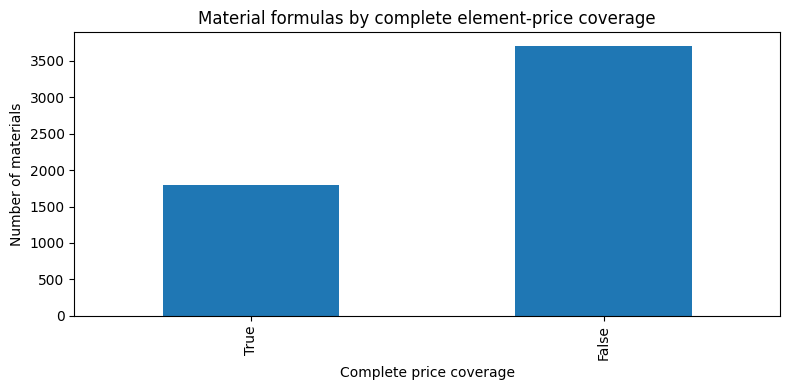

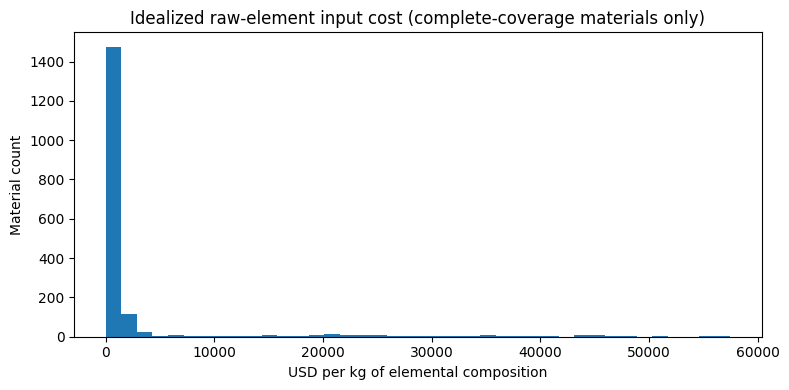

In [23]:
# Element coverage diagnostics and composition-cost distribution
element_use = []
for comp in materials["parsed_composition"].dropna():
    element_use.extend(comp.keys())
element_counts = pd.Series(element_use, dtype="object").value_counts().rename_axis("element").reset_index(name="material_formula_count")
element_counts["has_latest_price"] = element_counts["element"].isin(price_elements)
element_counts.to_csv(OUTPUT_DIR / "element_coverage_by_material_frequency.csv", index=False)

coverage_table = pd.DataFrame({
    "metric": [
        "total_material_rows", "formula_parse_success_rows",
        "complete_element_price_coverage_rows", "complete_element_price_coverage_rate",
        "latest_price_date", "elements_with_latest_price",
    ],
    "value": [
        len(materials), int(materials["formula_parse_ok"].sum()),
        int(materials["price_coverage_complete"].sum()), float(coverage_rate),
        str(latest_date.date()), int(len(latest_prices)),
    ],
})
display(coverage_table)
coverage_table.to_csv(OUTPUT_DIR / "material_price_coverage_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
materials["price_coverage_complete"].value_counts().reindex([True, False], fill_value=0).plot(
    kind="bar", ax=ax
)
ax.set_title("Material formulas by complete element-price coverage")
ax.set_xlabel("Complete price coverage")
ax.set_ylabel("Number of materials")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "material_price_coverage.png", dpi=140)
plt.show()

priced_costs = materials["raw_element_cost_usd_per_kg"].dropna()
if len(priced_costs):
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(priced_costs, bins=40)
    ax.set_title("Idealized raw-element input cost (complete-coverage materials only)")
    ax.set_xlabel("USD per kg of elemental composition")
    ax.set_ylabel("Material count")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "raw_element_cost_distribution.png", dpi=140)
    plt.show()


In [24]:
# DS-4 carbon-intensity and green-premium indicators: commodity-level only.
# Do not join these values onto individual material formulas.
carbon_cols = [
    "carbon_intensity_virgin", "carbon_intensity_recycled", "green_premium_per_kg"
]
for col in carbon_cols:
    ds4[col] = pd.to_numeric(ds4[col], errors="coerce")

carbon_summary = ds4.groupby("commodity")[carbon_cols].agg(["count", "mean", "median", "std"])
carbon_summary.columns = ["_".join(map(str, c)) for c in carbon_summary.columns]
carbon_summary = carbon_summary.reset_index()
display(carbon_summary)
carbon_summary.to_csv(OUTPUT_DIR / "commodity_carbon_indicator_summary.csv", index=False)

# Compare supplied virgin vs recycled intensity where both are present.
carbon_valid = ds4.dropna(subset=["carbon_intensity_virgin", "carbon_intensity_recycled"]).copy()
carbon_valid["absolute_intensity_difference"] = (
    carbon_valid["carbon_intensity_virgin"] - carbon_valid["carbon_intensity_recycled"]
)
carbon_valid["relative_reduction_vs_virgin_pct"] = np.where(
    carbon_valid["carbon_intensity_virgin"] > 0,
    100 * carbon_valid["absolute_intensity_difference"] / carbon_valid["carbon_intensity_virgin"],
    np.nan,
)
print("Rows where recycled intensity is lower than virgin:",
      f"{(carbon_valid['carbon_intensity_recycled'] < carbon_valid['carbon_intensity_virgin']).mean():.1%}")
display(carbon_valid[["commodity", *carbon_cols, "relative_reduction_vs_virgin_pct"]].head())


,commodity,carbon_intensity_virgin_count,carbon_intensity_virgin_mean,carbon_intensity_virgin_median,carbon_intensity_virgin_std,carbon_intensity_recycled_count,carbon_intensity_recycled_mean,carbon_intensity_recycled_median,carbon_intensity_recycled_std,green_premium_per_kg_count,green_premium_per_kg_mean,green_premium_per_kg_median,green_premium_per_kg_std
0,Aluminium,2869,12.001684,12.00,0.238323,2869,0.600167,0.6,0.018218,2869,0.849074,0.849,0.025253
1,Cobalt_Index,2869,22.004339,22.00,0.443148,2869,12.001729,12.0,0.368790,2869,4.098633,4.097,0.122616
2,Copper,2869,3.499240,3.50,0.069356,2869,1.199644,1.2,0.035693,2869,0.220001,0.220,0.006738
3,Iron_Ore,2869,1.800014,1.80,0.035978,2869,0.299888,0.3,0.009469,2869,0.080016,0.080,0.002400
4,Lithium_ETF,2869,15.001318,15.01,0.298715,2869,7.999024,8.0,0.239098,2869,2.502179,2.502,0.075621
5,Nickel,2869,8.002715,8.00,0.158725,2869,3.497776,3.5,0.104825,2869,1.199413,1.199,0.035204
6,RareEarth_ETF,2869,25.009348,25.01,0.494975,2869,0.000000,0.0,0.000000,2869,0.000000,0.000,0.000000
7,Steel_HRC,2869,2.098397,2.10,0.042428,2869,0.400356,0.4,0.012288,2869,0.149776,0.150,0.004521


Rows where recycled intensity is lower than virgin: 100.0%


,commodity,carbon_intensity_virgin,carbon_intensity_recycled,green_premium_per_kg,relative_reduction_vs_virgin_pct
0,Steel_HRC,2.08,0.42,0.149,79.807692
1,Steel_HRC,2.11,0.40,0.147,81.042654
2,Steel_HRC,2.08,0.39,0.152,81.250000
3,Steel_HRC,2.16,0.41,0.144,81.018519
4,Steel_HRC,2.08,0.39,0.149,81.250000


In [25]:
# Outputs and run summary
OUTPUT_DIR = ROOT / "ML" / "outputs" / "notebook_06"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Re-write outputs after OUTPUT_DIR initialization in case execution order was changed.
element_counts.to_csv(OUTPUT_DIR / "element_coverage_by_material_frequency.csv", index=False)
coverage_table.to_csv(OUTPUT_DIR / "material_price_coverage_summary.csv", index=False)
carbon_summary.to_csv(OUTPUT_DIR / "commodity_carbon_indicator_summary.csv", index=False)
materials.drop(columns=["parsed_composition"]).to_csv(
    OUTPUT_DIR / "material_element_cost_estimates.csv", index=False
)

summary = {
    "notebook": "06_esg_element_price_coverage",
    "dataset_rows": {"DS1": int(len(ds1)), "DS5": int(len(ds5)), "DS4": int(len(ds4))},
    "formula_parse_success_rate": float(ds1["formula_parse_ok"].mean()),
    "complete_latest_element_price_coverage_rate": float(coverage_rate),
    "latest_element_price_date": str(latest_date.date()),
    "elements_with_latest_price": int(len(latest_prices)),
    "raw_element_cost_rows": int(materials["raw_element_cost_usd_per_kg"].notna().sum()),
    "limitations": [
        "Raw-element cost proxy excludes manufacturing, processing, energy, transport, waste and lifecycle costs.",
        "Only formulas with complete element price coverage receive a cost estimate.",
        "DS-4 carbon intensity values are commodity-level indicators, not material-specific lifecycle assessments.",
        "No complete ESG score is computed because environmental, social and governance coverage is insufficient.",
        "Results are exploratory and depend on the supplied dataset provenance."
    ],
    "outputs": [
        "element_coverage_by_material_frequency.csv",
        "material_price_coverage_summary.csv",
        "commodity_carbon_indicator_summary.csv",
        "material_element_cost_estimates.csv",
        "material_price_coverage.png",
        "raw_element_cost_distribution.png"
    ],
}
with open(OUTPUT_DIR / "run_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))
print("Output directory:", OUTPUT_DIR.resolve())


{
  "notebook": "06_esg_element_price_coverage",
  "dataset_rows": {
    "DS1": 5500,
    "DS5": 5280,
    "DS4": 22952
  },
  "formula_parse_success_rate": 1.0,
  "complete_latest_element_price_coverage_rate": 0.32636363636363636,
  "latest_element_price_date": "2024-12-01",
  "elements_with_latest_price": 40,
  "raw_element_cost_rows": 1795,
  "limitations": [
    "Raw-element cost proxy excludes manufacturing, processing, energy, transport, waste and lifecycle costs.",
    "Only formulas with complete element price coverage receive a cost estimate.",
    "DS-4 carbon intensity values are commodity-level indicators, not material-specific lifecycle assessments.",
    "No complete ESG score is computed because environmental, social and governance coverage is insufficient.",
    "Results are exploratory and depend on the supplied dataset provenance."
  ],
  "outputs": [
    "element_coverage_by_material_frequency.csv",
    "material_price_coverage_summary.csv",
    "commodity_carbon_ind